# 01 · Pengambilan Data & Eksplorasi Data (EDA)
## Early Warning System Harga Pangan Strategis Kab/Kota Jawa Barat

**UAS AI for Innovation — Magister Inovasi Regional 2026/2027**

Notebook ini menjawab komponen laporan:
- **(f) Justifikasi ketersediaan data** — sumber, cakupan, kualitas, keterbatasan
- **(g) Eksplorasi data** — kualitas data, statistik deskriptif, visualisasi, pola

**Sumber data:** Pusat Informasi Harga Pangan Strategis Nasional (PIHPS), Bank Indonesia — harga harian pasar tradisional, <https://www.bi.go.id/hargapangan>.
Data ditarik lewat endpoint JSON situs PIHPS dengan skrip `scripts/fetch_pihps.py` (bisa diulang/reproducible).

**Struktur notebook**
1. Setup & memuat data
2. Gambaran umum dataset
3. Pemeriksaan kualitas data
4. Statistik deskriptif komoditas fokus
5. Tren harga
6. Pola musiman & efek Lebaran
7. Volatilitas & frekuensi lonjakan
8. Perbandingan & keterkaitan antar daerah
9. Autokorelasi & stasioneritas (dasar pemodelan)
10. Ekspor data mingguan untuk notebook analisis
11. Ringkasan temuan EDA

## 1. Setup & memuat data

In [1]:
# Di Google Colab library berikut sudah tersedia; statsmodels juga sudah terpasang.
import warnings, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
rupiah = mtick.FuncFormatter(lambda x, _: f"Rp{x/1000:,.0f}rb")

In [2]:
# Data mentah disimpan di repositori GitHub proyek.
# - Dijalankan lokal dari folder notebooks/  -> baca file lokal
# - Dijalankan di Colab                       -> baca langsung dari GitHub
REPO_RAW = "https://raw.githubusercontent.com/dansek/ews-harga-pangan-jabar/main"
REL_PATH = "data/raw/pihps_jabar_harian.csv.gz"

local = Path("..") / REL_PATH
src = local if local.exists() else f"{REPO_RAW}/{REL_PATH}"
raw = pd.read_csv(src, parse_dates=["tanggal"])
print("Sumber:", src)
raw.head()

Sumber: ../data/raw/pihps_jabar_harian.csv.gz


,tanggal,kabkota_id,kabkota,kategori,komoditas,harga
0,2019-01-01,103,Kab. Cirebon,Bawang Merah,Bawang Merah Ukuran Sedang,NaN
1,2019-01-02,103,Kab. Cirebon,Bawang Merah,Bawang Merah Ukuran Sedang,"27,000.00"
2,2019-01-03,103,Kab. Cirebon,Bawang Merah,Bawang Merah Ukuran Sedang,"27,000.00"
3,2019-01-04,103,Kab. Cirebon,Bawang Merah,Bawang Merah Ukuran Sedang,"27,000.00"
4,2019-01-07,103,Kab. Cirebon,Bawang Merah,Bawang Merah Ukuran Sedang,"27,000.00"


> **Alternatif:** jika ingin menarik ulang data terbaru langsung dari PIHPS, jalankan
> `!python scripts/fetch_pihps.py` setelah meng-*clone* repositori. Proses ±5 menit.

## 2. Gambaran umum dataset

In [3]:
print(f"Jumlah baris          : {len(raw):,}")
print(f"Periode               : {raw.tanggal.min():%d %b %Y} s.d. {raw.tanggal.max():%d %b %Y}")
print(f"Jumlah hari tercatat  : {raw.tanggal.nunique():,}")
print(f"Jumlah kab/kota       : {raw.kabkota.nunique()}")
print(f"Jumlah komoditas      : {raw.komoditas.nunique()}")
print("\nKab/kota:", ", ".join(sorted(raw.kabkota.unique())))
raw.info()

Jumlah baris          : 389,529
Periode               : 01 Jan 2019 s.d. 24 Nov 2026
Jumlah hari tercatat  : 2,061
Jumlah kab/kota       : 9
Jumlah komoditas      : 21

Kab/kota: Kab. Cirebon, Kab. Tasikmalaya, Kota Bandung, Kota Bekasi, Kota Bogor, Kota Cirebon, Kota Depok, Kota Sukabumi, Kota Tasikmalaya
<class 'pandas.DataFrame'>
RangeIndex: 389529 entries, 0 to 389528
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   tanggal     389529 non-null  datetime64[us]
 1   kabkota_id  389529 non-null  int64         
 2   kabkota     389529 non-null  str           
 3   kategori    389529 non-null  str           
 4   komoditas   389529 non-null  str           
 5   harga       376124 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 17.8 MB


In [4]:
raw.groupby("kategori").komoditas.unique().to_frame("komoditas dalam kategori")

,komoditas dalam kategori
kategori,
Bawang Merah,[Bawang Merah Ukuran Sedang]
Bawang Putih,[Bawang Putih Ukuran Sedang]
Beras,"[Beras Kualitas Bawah I, Beras Kualitas Bawah ..."
Cabai Merah,"[Cabai Merah Besar, Cabai Merah Keriting]"
Cabai Rawit,"[Cabai Rawit Hijau, Cabai Rawit Merah]"
Daging Ayam,[Daging Ayam Ras Segar]
Daging Sapi,"[Daging Sapi Kualitas 1, Daging Sapi Kualitas 2]"
Gula Pasir,"[Gula Pasir Kualitas Premium, Gula Pasir Lokal]"
Minyak Goreng,"[Minyak Goreng Curah, Minyak Goreng Kemasan Be..."


In [5]:
# Hari pencatatan: PIHPS hanya mencatat hari kerja
raw.drop_duplicates("tanggal").tanggal.dt.day_name().value_counts()

tanggal
Tuesday      413
Wednesday    412
Thursday     412
Friday       412
Monday       412
Name: count, dtype: int64

### Komoditas fokus
Dipilih 5 komoditas yang paling berpengaruh terhadap inflasi pangan (*volatile food*) di Jawa Barat:

In [6]:
FOKUS = {
    "Beras Kualitas Medium I":    "Beras Medium",
    "Cabai Merah Keriting":       "Cabai Merah Keriting",
    "Cabai Rawit Merah":          "Cabai Rawit Merah",
    "Bawang Merah Ukuran Sedang": "Bawang Merah",
    "Bawang Putih Ukuran Sedang": "Bawang Putih",
}
df = raw[raw.komoditas.isin(FOKUS)].copy()
df["komoditas"] = df.komoditas.map(FOKUS)
KOM = list(FOKUS.values())
KAB = sorted(df.kabkota.unique())
print(f"{len(df):,} baris untuk {len(KOM)} komoditas x {len(KAB)} kab/kota")

92,745 baris untuk 5 komoditas x 9 kab/kota


## 3. Pemeriksaan kualitas data

### 3a. Nilai hilang (missing) per kab/kota × komoditas

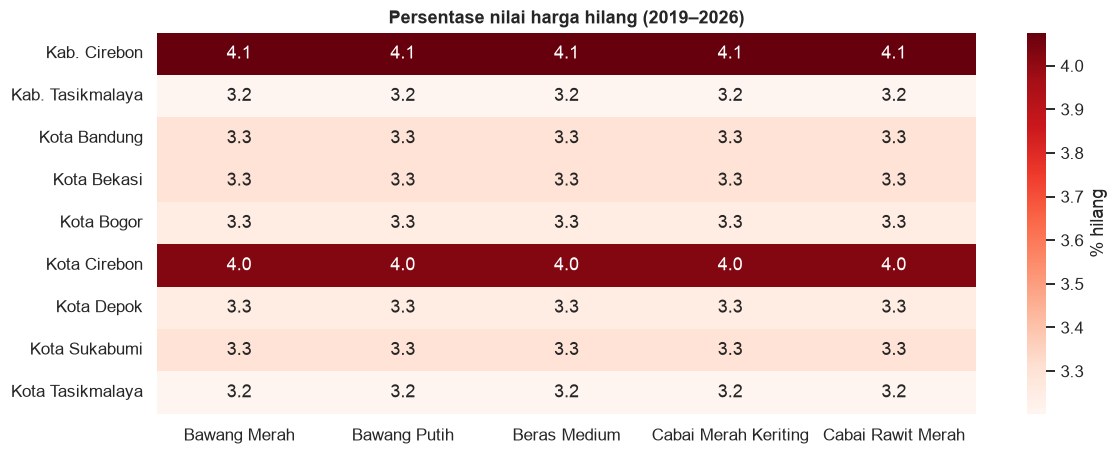

Total nilai hilang komoditas fokus: 3.43%


In [7]:
miss = (df.assign(hilang=df.harga.isna())
          .pivot_table(index="kabkota", columns="komoditas", values="hilang", aggfunc="mean") * 100)
ax = sns.heatmap(miss, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% hilang"})
ax.set_title("Persentase nilai harga hilang (2019–2026)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()
print(f"Total nilai hilang komoditas fokus: {df.harga.isna().mean()*100:.2f}%")

### 3b. Kelengkapan per tahun

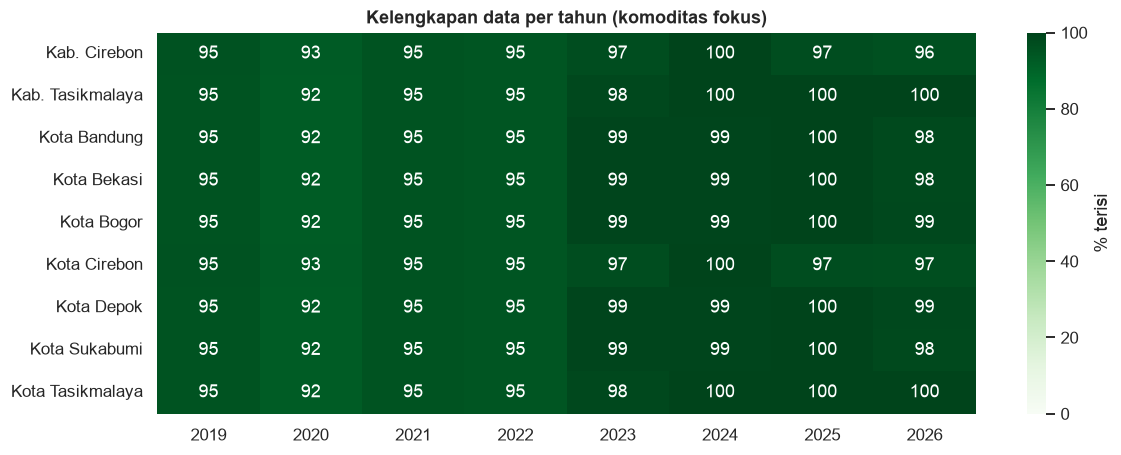

In [8]:
cov = (df.assign(tahun=df.tanggal.dt.year, ada=df.harga.notna())
         .pivot_table(index="kabkota", columns="tahun", values="ada", aggfunc="mean") * 100)
ax = sns.heatmap(cov, annot=True, fmt=".0f", cmap="Greens", vmin=0, vmax=100, cbar_kws={"label": "% terisi"})
ax.set_title("Kelengkapan data per tahun (komoditas fokus)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

### 3c. Duplikasi, nilai tidak wajar, dan lompatan ekstrem

In [9]:
print("Duplikat (tanggal, kab/kota, komoditas):", df.duplicated(["tanggal", "kabkota", "komoditas"]).sum())
print("Harga <= 0                              :", (df.harga <= 0).sum())

d = df.sort_values(["kabkota", "komoditas", "tanggal"]).copy()
d["chg"] = d.groupby(["kabkota", "komoditas"]).harga.pct_change(fill_method=None)
ekstrem = d[d.chg.abs() > 0.5]
print(f"Perubahan harian > 50%                  : {len(ekstrem)} kejadian "
      f"({len(ekstrem)/d.chg.notna().sum()*100:.3f}% dari observasi)")
ekstrem.sort_values("chg", key=abs, ascending=False).head(10)[["tanggal", "kabkota", "komoditas", "harga", "chg"]]

Duplikat (tanggal, kab/kota, komoditas): 0
Harga <= 0                              : 0
Perubahan harian > 50%                  : 28 kejadian (0.032% dari observasi)


,tanggal,kabkota,komoditas,harga,chg
283018,2021-07-14,Kota Depok,Cabai Rawit Merah,"227,500.00",2.43
283048,2021-08-25,Kota Depok,Cabai Rawit Merah,"82,500.00",2.00
327452,2025-12-15,Kota Sukabumi,Cabai Rawit Merah,"264,250.00",1.94
348398,2019-05-06,Kota Tasikmalaya,Bawang Putih,"100,000.00",1.08
150080,2025-06-20,Kota Bekasi,Cabai Merah Keriting,"75,000.00",0.94
45431,2019-05-06,Kab. Tasikmalaya,Bawang Putih,"90,000.00",0.88
193361,2025-06-20,Kota Bogor,Cabai Merah Keriting,"57,500.00",0.70
321625,2019-06-03,Kota Sukabumi,Cabai Merah Keriting,"61,250.00",0.70
283019,2021-07-15,Kota Depok,Cabai Rawit Merah,"70,000.00",-0.69
321640,2019-06-24,Kota Sukabumi,Cabai Merah Keriting,"58,250.00",0.69


Lompatan harian > 50% bisa berupa lonjakan pasar yang nyata (umum pada cabai) **atau** salah input.
Untuk membedakannya, dicek apakah harga **kembali** ke level semula keesokan harinya (pola *spike* tunggal = indikasi salah input).

In [10]:
d["chg_next"] = d.groupby(["kabkota", "komoditas"]).chg.shift(-1)
glitch = d[(d.chg.abs() > 0.5) & (np.sign(d.chg) != np.sign(d.chg_next)) & (d.chg_next.abs() > 0.3)]
print(f"Spike tunggal (naik lalu langsung turun / sebaliknya): {len(glitch)} titik -> diperlakukan sebagai outlier")
glitch[["tanggal", "kabkota", "komoditas", "harga", "chg", "chg_next"]].head(10)

Spike tunggal (naik lalu langsung turun / sebaliknya): 3 titik -> diperlakukan sebagai outlier


,tanggal,kabkota,komoditas,harga,chg,chg_next
283018,2021-07-14,Kota Depok,Cabai Rawit Merah,"227,500.00",2.43,-0.69
283048,2021-08-25,Kota Depok,Cabai Rawit Merah,"82,500.00",2.00,-0.69
327452,2025-12-15,Kota Sukabumi,Cabai Rawit Merah,"264,250.00",1.94,-0.69


### 3d. Nilai yang tidak berubah lama (*stale*)

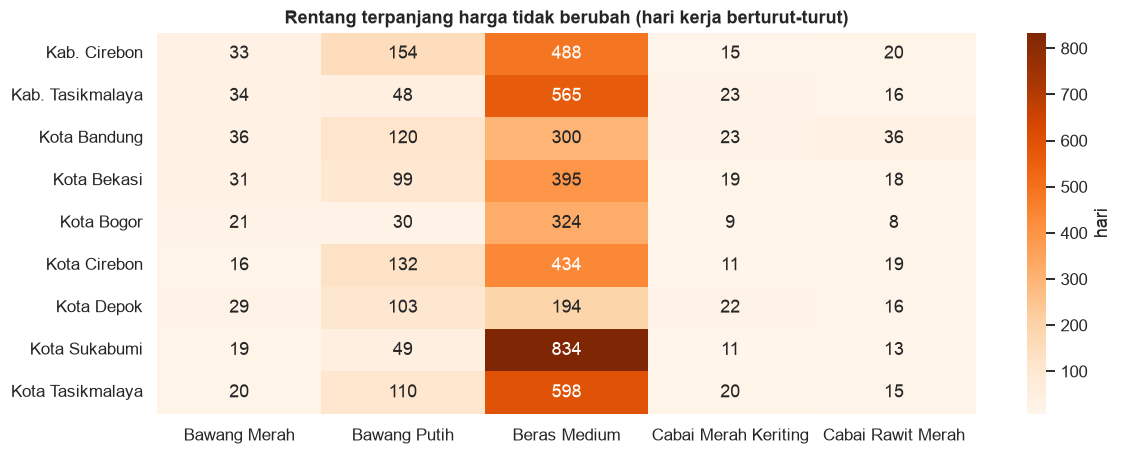

In [11]:
def max_run(s):
    g = (s != s.shift()).cumsum()
    return s.groupby(g).size().max()

stale = (df.sort_values("tanggal").dropna(subset=["harga"])
           .groupby(["kabkota", "komoditas"]).harga.apply(max_run).unstack())
ax = sns.heatmap(stale, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "hari"})
ax.set_title("Rentang terpanjang harga tidak berubah (hari kerja berturut-turut)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

Beras medium wajar stabil lama (harga dikendalikan HET/SPHP). Pada cabai/bawang, rentang datar yang panjang
patut dicatat sebagai keterbatasan data (kemungkinan pasar tidak memperbarui laporan).

### 3e. Pembersihan & agregasi mingguan

Keputusan pembersihan:
1. Spike tunggal (3c) dijadikan `NaN`.
2. Data diagregasi ke **mingguan (median, minggu berakhir Jumat)** — mengurangi derau harian, menyamakan
   frekuensi dengan siklus keputusan TPID (rapat/operasi pasar mingguan), dan mengatasi hari libur.
3. Celah mingguan pendek (≤ 3 minggu) diisi interpolasi linier; celah lebih panjang dibiarkan.

In [12]:
clean = d.copy()
clean.loc[glitch.index, "harga"] = np.nan

wk = (clean.set_index("tanggal")
           .groupby(["kabkota", "komoditas"]).harga
           .resample("W-FRI").median()
           .reset_index())
wk["harga_isi"] = (wk.groupby(["kabkota", "komoditas"]).harga
                     .transform(lambda s: s.interpolate(limit=3, limit_area="inside")))
print(f"Data mingguan: {len(wk):,} baris; nilai hilang setelah interpolasi: {wk.harga_isi.isna().mean()*100:.2f}%")
wk.head()

Data mingguan: 18,585 baris; nilai hilang setelah interpolasi: 0.00%


,kabkota,komoditas,tanggal,harga,harga_isi
0,Kab. Cirebon,Bawang Merah,2019-01-04,"27,000.00","27,000.00"
1,Kab. Cirebon,Bawang Merah,2019-01-11,"26,000.00","26,000.00"
2,Kab. Cirebon,Bawang Merah,2019-01-18,"25,000.00","25,000.00"
3,Kab. Cirebon,Bawang Merah,2019-01-25,"20,500.00","20,500.00"
4,Kab. Cirebon,Bawang Merah,2019-02-01,"20,000.00","20,000.00"


## 4. Statistik deskriptif komoditas fokus

In [13]:
desc = (wk.groupby("komoditas").harga_isi
          .agg(rata2="mean", median="median", std="std", min="min", maks="max")
          .assign(CV_persen=lambda x: x["std"] / x["rata2"] * 100)
          .loc[KOM])
desc

,rata2,median,std,min,maks,CV_persen
komoditas,,,,,,
Beras Medium,"13,059.08","12,500.00","1,854.97","10,500.00","16,700.00",14.20
Cabai Merah Keriting,"46,612.53","45,000.00","16,908.94","14,250.00","123,750.00",36.28
Cabai Rawit Merah,"57,751.39","52,500.00","22,724.26","21,000.00","140,000.00",39.35
Bawang Merah,"36,518.87","34,500.00","9,791.36","16,000.00","80,000.00",26.81
Bawang Putih,"35,573.95","35,250.00","8,165.82","15,500.00","71,250.00",22.95


*Coefficient of Variation (CV)* menunjukkan seberapa bergejolak harga relatif terhadap rata-ratanya.

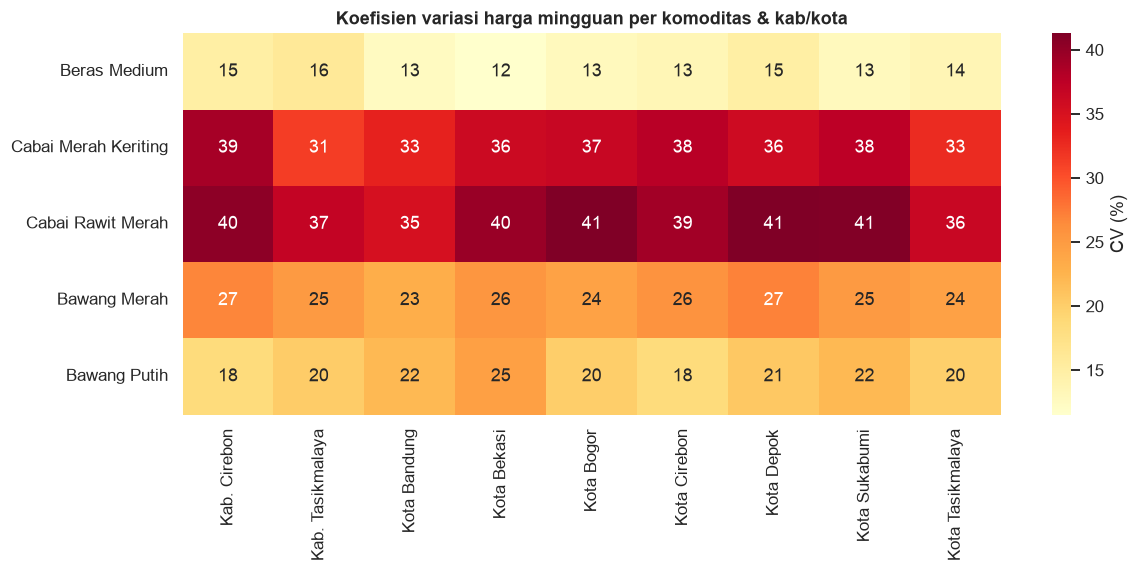

In [14]:
cv_kab = (wk.groupby(["komoditas", "kabkota"]).harga_isi
            .agg(lambda s: s.std() / s.mean() * 100).unstack().loc[KOM])
ax = sns.heatmap(cv_kab, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "CV (%)"})
ax.set_title("Koefisien variasi harga mingguan per komoditas & kab/kota"); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

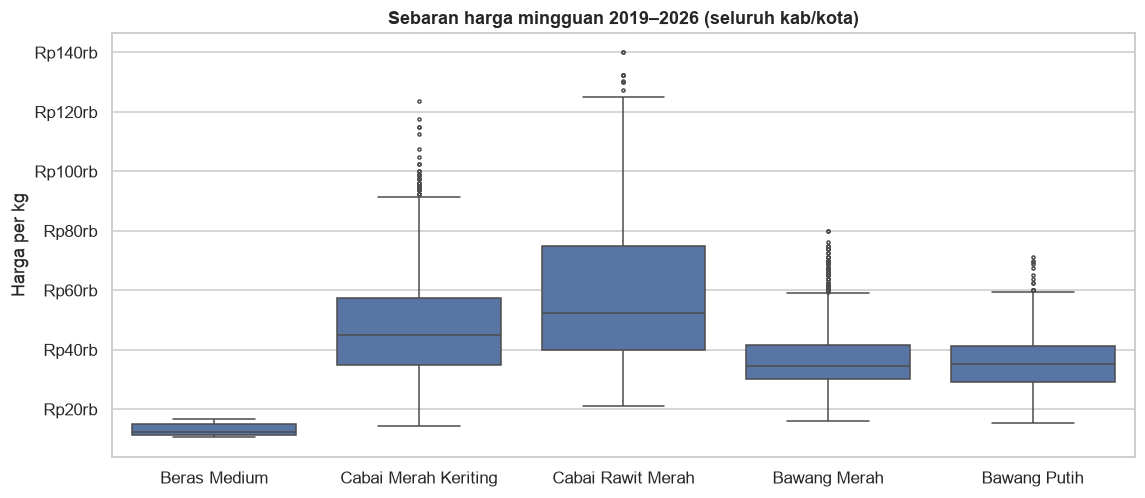

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=wk, x="komoditas", y="harga_isi", order=KOM, ax=ax, fliersize=2)
ax.yaxis.set_major_formatter(rupiah); ax.set_xlabel(""); ax.set_ylabel("Harga per kg")
ax.set_title("Sebaran harga mingguan 2019–2026 (seluruh kab/kota)")
plt.show()

## 5. Tren harga

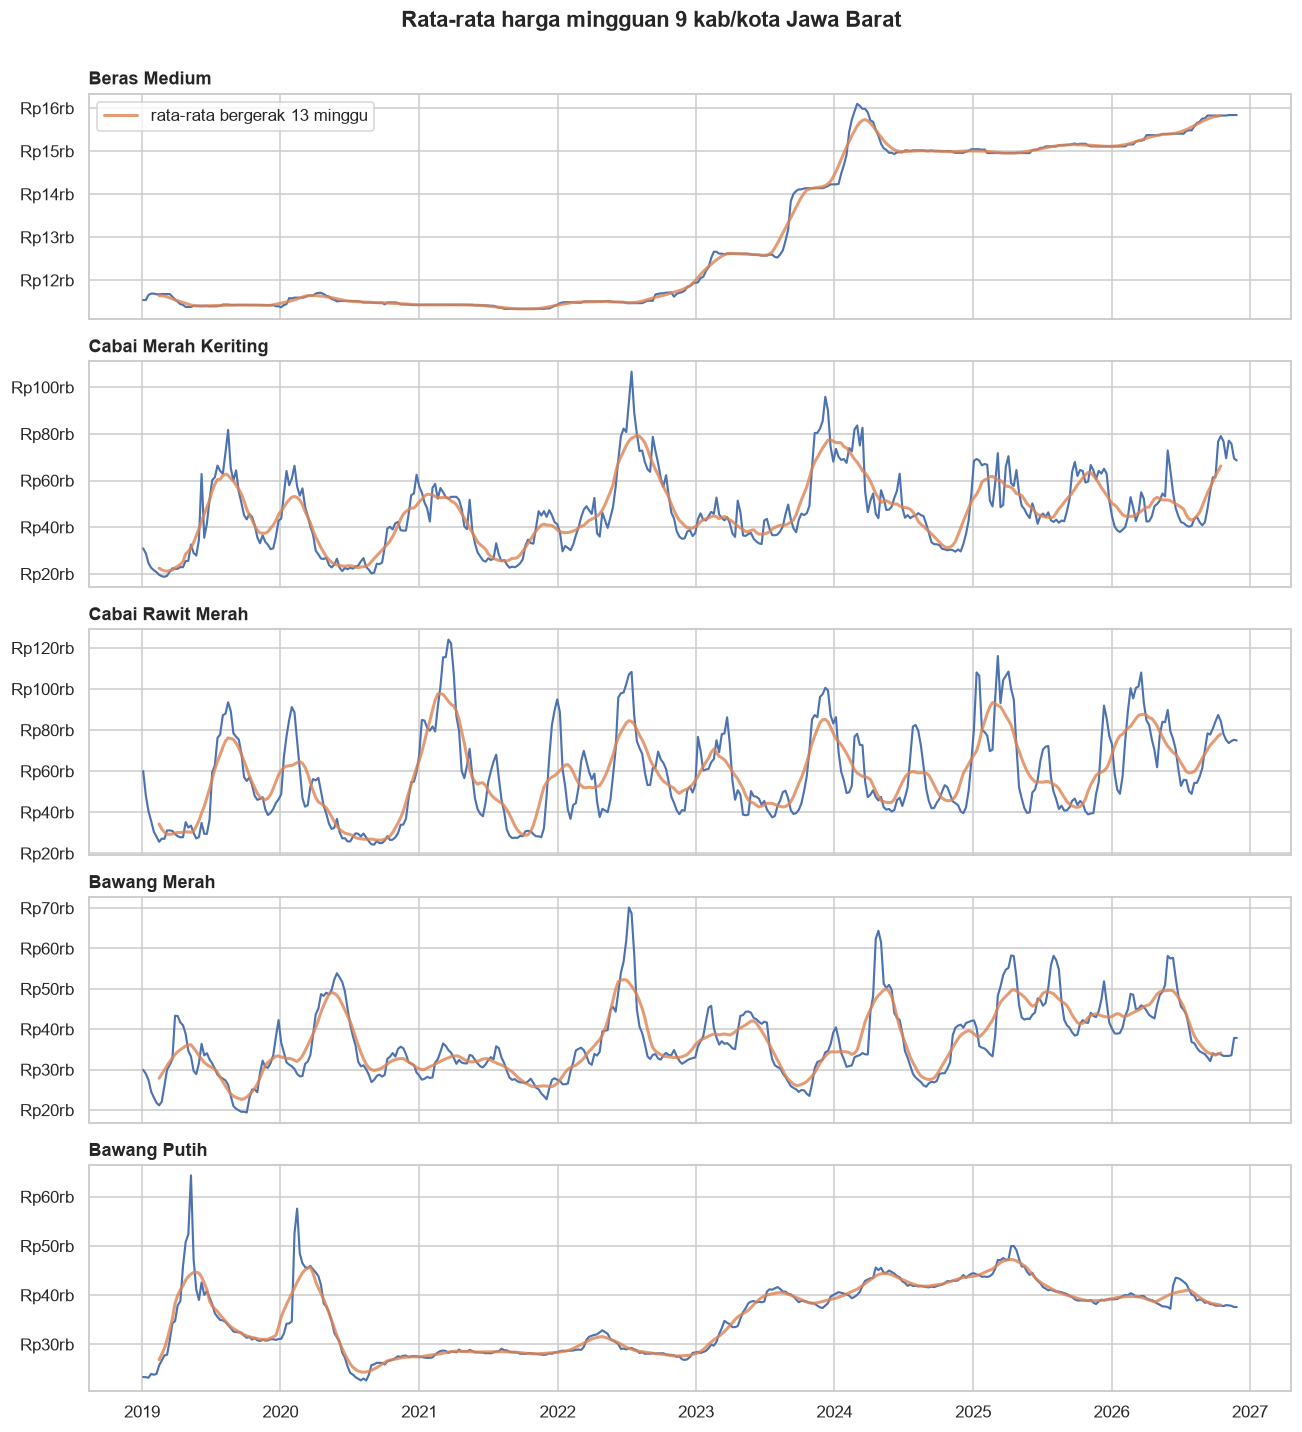

In [16]:
jabar = wk.groupby(["tanggal", "komoditas"]).harga_isi.mean().unstack()[KOM]
fig, axes = plt.subplots(len(KOM), 1, figsize=(12, 13), sharex=True)
for ax, k in zip(axes, KOM):
    ax.plot(jabar.index, jabar[k], lw=1.4)
    ax.plot(jabar.index, jabar[k].rolling(13, center=True).mean(), lw=2, alpha=.8, label="rata-rata bergerak 13 minggu")
    ax.set_title(k, loc="left"); ax.yaxis.set_major_formatter(rupiah)
axes[0].legend(loc="upper left")
fig.suptitle("Rata-rata harga mingguan 9 kab/kota Jawa Barat", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

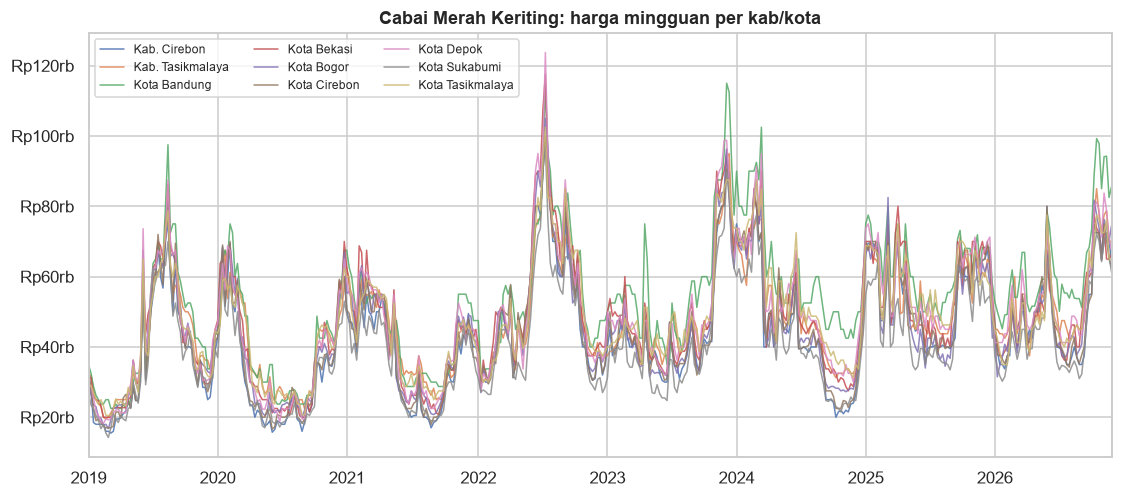

In [17]:
k = "Cabai Merah Keriting"
piv = wk[wk.komoditas == k].pivot(index="tanggal", columns="kabkota", values="harga_isi")
ax = piv.plot(figsize=(12, 5), lw=1, alpha=.85)
ax.yaxis.set_major_formatter(rupiah); ax.set_title(f"{k}: harga mingguan per kab/kota"); ax.set_xlabel("")
ax.legend(ncol=3, fontsize=8); plt.show()

In [18]:
tahunan = (wk.assign(tahun=wk.tanggal.dt.year).groupby(["komoditas", "tahun"]).harga_isi.mean().unstack().loc[KOM])
(tahunan.pct_change(axis=1) * 100).round(1).iloc[:, 1:].style.format("{:+.1f}%").background_gradient(cmap="RdYlGn_r", axis=None) \
    .set_caption("Perubahan rata-rata harga tahunan (%)")

tahun,2020,2021,2022,2023,2024,2025,2026
komoditas,,,,,,,
Beras Medium,+0.5%,-1.2%,+1.6%,+13.0%,+15.8%,-0.5%,+2.8%
Cabai Merah Keriting,-7.1%,+9.6%,+34.6%,-9.0%,+1.8%,+13.3%,-7.1%
Cabai Rawit Merah,-11.5%,+46.8%,-0.7%,-1.1%,-10.1%,+21.4%,+13.3%
Bawang Merah,+23.4%,-17.5%,+26.3%,-7.2%,+6.0%,+21.1%,-7.4%
Bawang Putih,-5.5%,-12.4%,+3.1%,+26.0%,+15.8%,+0.2%,-7.7%


## 6. Pola musiman & efek Lebaran

### 6a. Profil bulanan

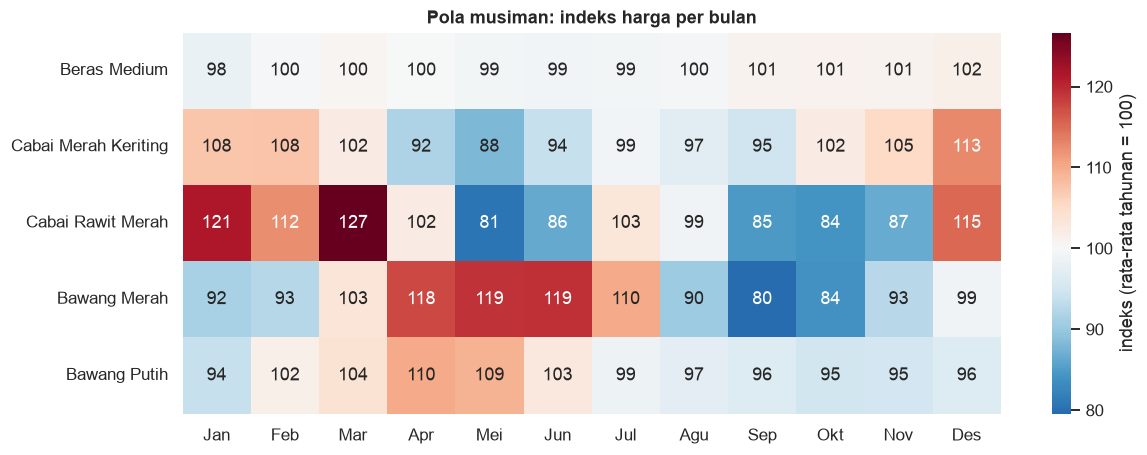

In [19]:
m = wk.copy()
m["tahun"], m["bulan"] = m.tanggal.dt.year, m.tanggal.dt.month
# indeks: harga dibagi rata-rata tahunannya (menghilangkan efek tren)
m["indeks"] = m.harga_isi / m.groupby(["kabkota", "komoditas", "tahun"]).harga_isi.transform("mean") * 100
prof = m.groupby(["komoditas", "bulan"]).indeks.mean().unstack().loc[KOM]
prof.columns = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
ax = sns.heatmap(prof, annot=True, fmt=".0f", cmap="RdBu_r", center=100, cbar_kws={"label": "indeks (rata-rata tahunan = 100)"})
ax.set_title("Pola musiman: indeks harga per bulan"); ax.set_xlabel(""); ax.set_ylabel(""); plt.show()

### 6b. Dekomposisi STL (tren – musiman – residu)

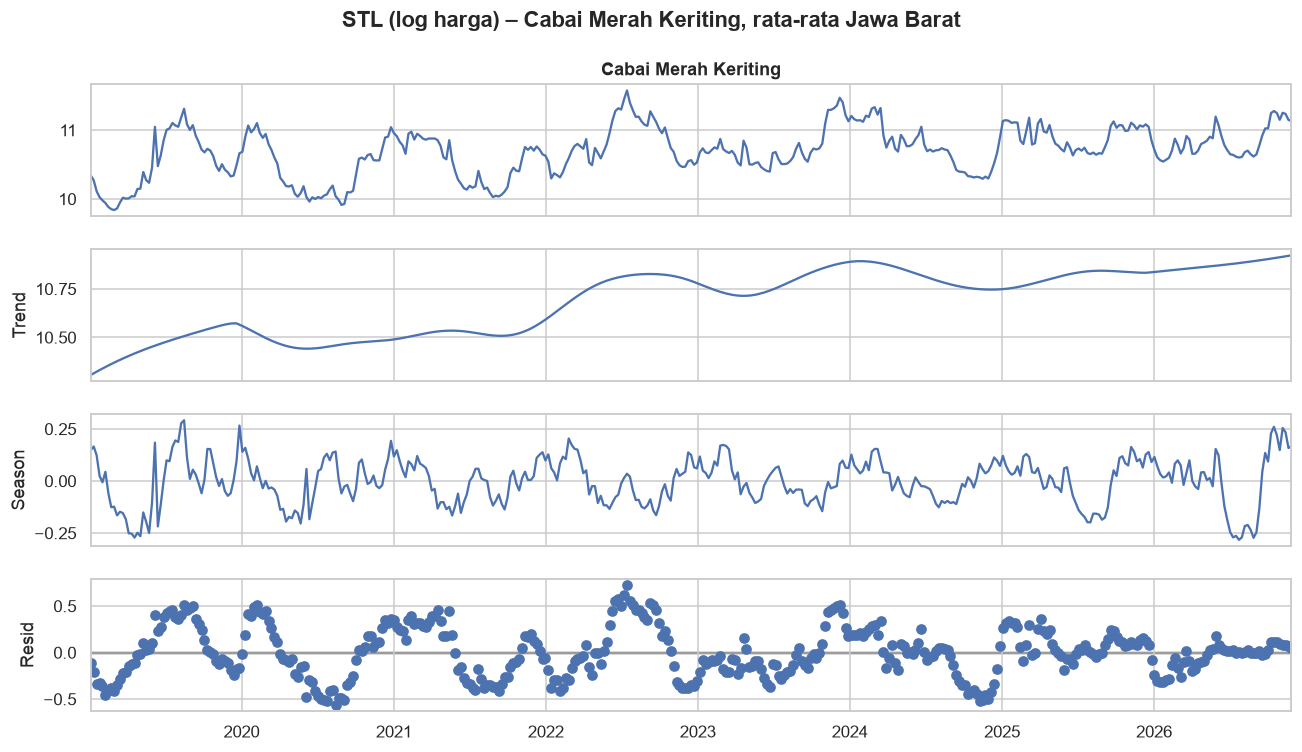

Cabai Merah Keriting: kekuatan musiman = 0.18  (0 = tidak ada, 1 = sangat kuat)


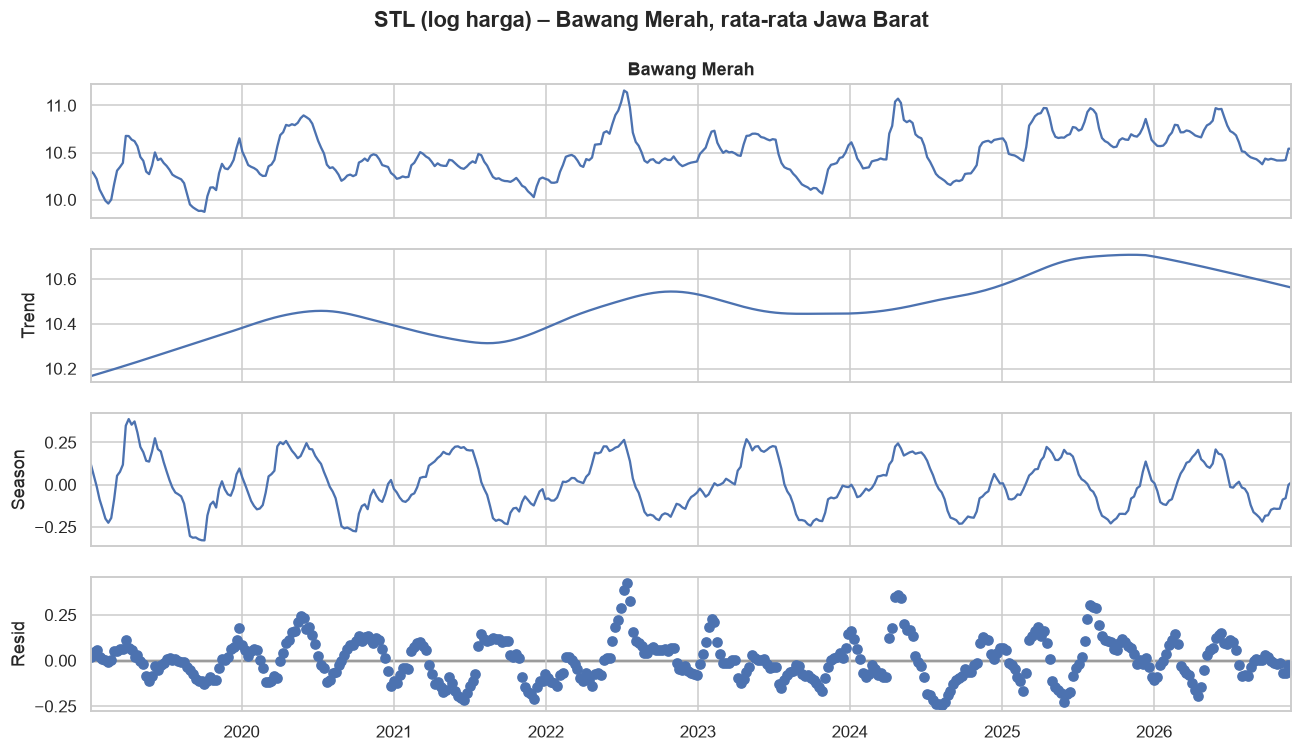

Bawang Merah: kekuatan musiman = 0.66  (0 = tidak ada, 1 = sangat kuat)


In [20]:
for k in ["Cabai Merah Keriting", "Bawang Merah"]:
    s = jabar[k].dropna().asfreq("W-FRI").interpolate()
    res = STL(np.log(s), period=52).fit()  # non-robust: lonjakan tidak dibuang ke residu
    fig = res.plot(); fig.set_size_inches(12, 7)
    fig.suptitle(f"STL (log harga) – {k}, rata-rata Jawa Barat", y=1.01, fontweight="bold")
    plt.show()
    print(f"{k}: kekuatan musiman = {max(0, 1 - np.var(res.resid)/np.var(res.seasonal + res.resid)):.2f}  "
          f"(0 = tidak ada, 1 = sangat kuat)")

### 6c. Efek Idulfitri (*event study*)

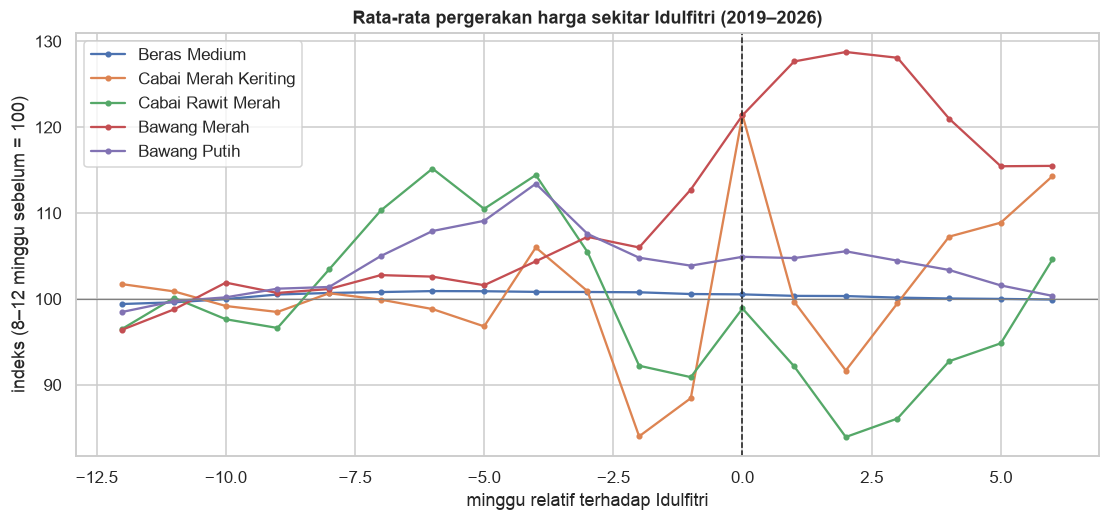

In [21]:
LEBARAN = pd.to_datetime(["2019-06-05", "2020-05-24", "2021-05-13", "2022-05-02",
                          "2023-04-22", "2024-04-10", "2025-03-31", "2026-03-20"])
rows = []
for L in LEBARAN:
    base = jabar.loc[L - pd.Timedelta(weeks=12): L - pd.Timedelta(weeks=8)].mean()
    for w in range(-12, 7):
        t = L + pd.Timedelta(weeks=w)
        near = jabar.index[np.argmin(np.abs(jabar.index - t))]
        rows.append({"minggu": w, "tahun": L.year, **(jabar.loc[near] / base * 100).to_dict()})
ev = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(12, 5))
for k in KOM:
    ax.plot(ev.groupby("minggu")[k].mean(), marker="o", ms=3, label=k)
ax.axvline(0, color="k", ls="--", lw=1); ax.axhline(100, color="grey", lw=.8)
ax.set_xlabel("minggu relatif terhadap Idulfitri"); ax.set_ylabel("indeks (8–12 minggu sebelum = 100)")
ax.set_title("Rata-rata pergerakan harga sekitar Idulfitri (2019–2026)"); ax.legend(); plt.show()

## 7. Volatilitas & frekuensi lonjakan

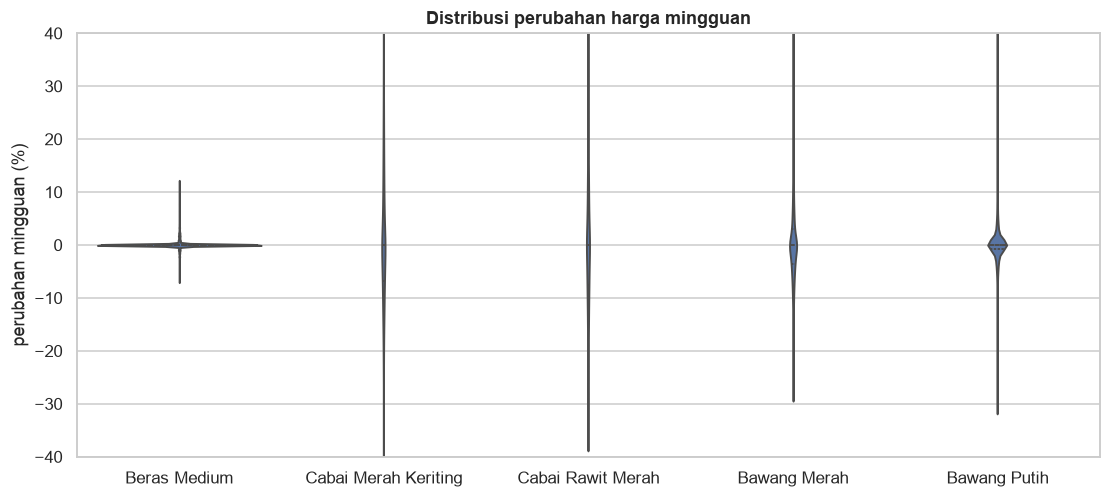

In [22]:
wk = wk.sort_values("tanggal")
wk["ret"] = wk.groupby(["kabkota", "komoditas"]).harga_isi.pct_change(fill_method=None) * 100
fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=wk, x="komoditas", y="ret", order=KOM, cut=0, inner="quartile", ax=ax)
ax.set_ylim(-40, 40); ax.set_ylabel("perubahan mingguan (%)"); ax.set_xlabel("")
ax.set_title("Distribusi perubahan harga mingguan"); plt.show()

**Definisi lonjakan** (dipakai juga di notebook analisis): harga naik **> 10 %** dalam 4 minggu
dibandingkan harga 4 minggu sebelumnya.

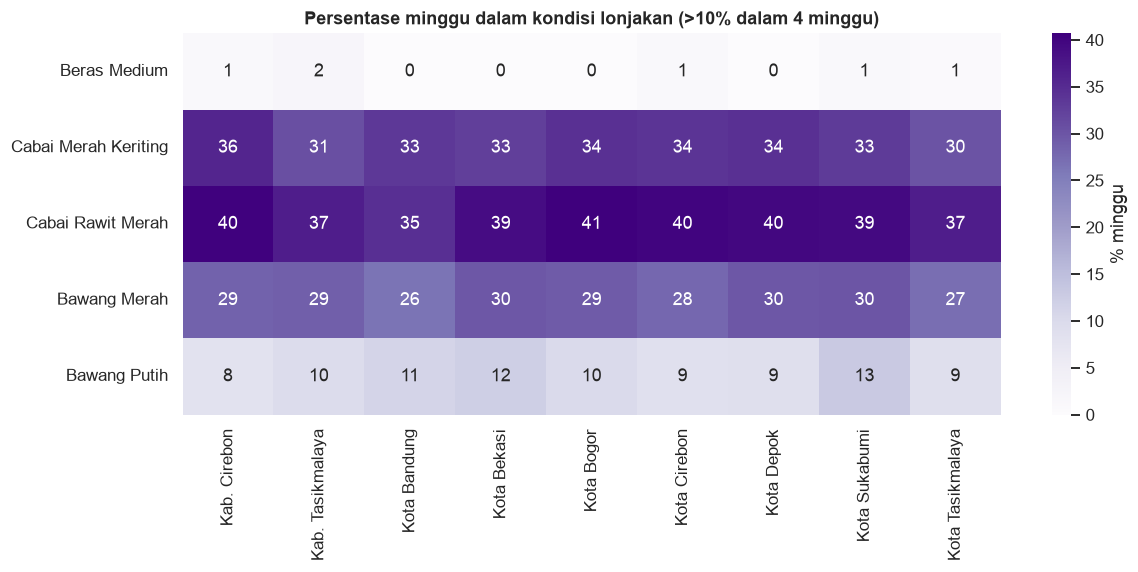

In [23]:
wk["naik4w"] = wk.groupby(["kabkota", "komoditas"]).harga_isi.pct_change(4, fill_method=None) * 100
wk["lonjakan"] = wk.naik4w > 10
freq = wk.groupby(["komoditas", "kabkota"]).lonjakan.mean().unstack().loc[KOM] * 100
ax = sns.heatmap(freq, annot=True, fmt=".0f", cmap="Purples", cbar_kws={"label": "% minggu"})
ax.set_title("Persentase minggu dalam kondisi lonjakan (>10% dalam 4 minggu)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

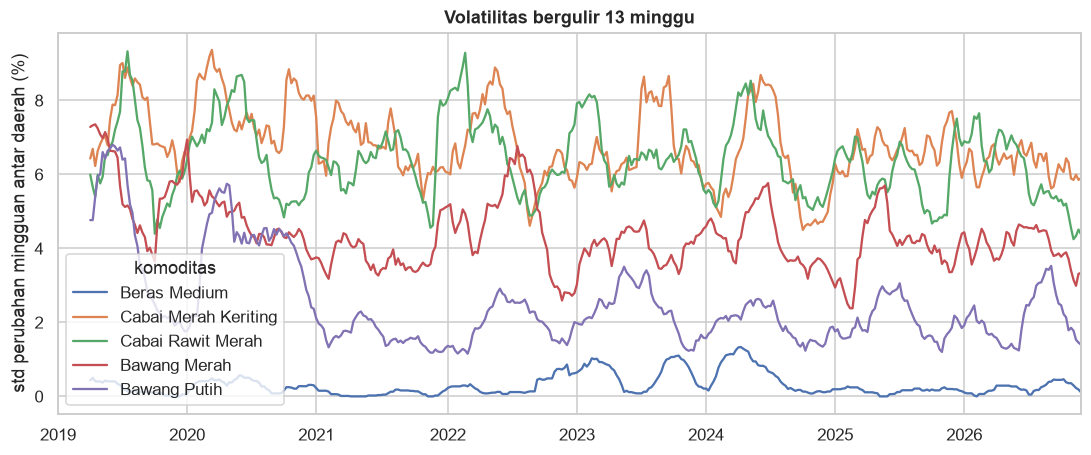

In [24]:
vol = (wk.groupby(["tanggal", "komoditas"]).ret.std().unstack()[KOM]
         .rolling(13).mean())
ax = vol.plot(figsize=(12, 4.5)); ax.set_ylabel("std perubahan mingguan antar daerah (%)")
ax.set_title("Volatilitas bergulir 13 minggu"); ax.set_xlabel(""); plt.show()

## 8. Perbandingan & keterkaitan antar daerah

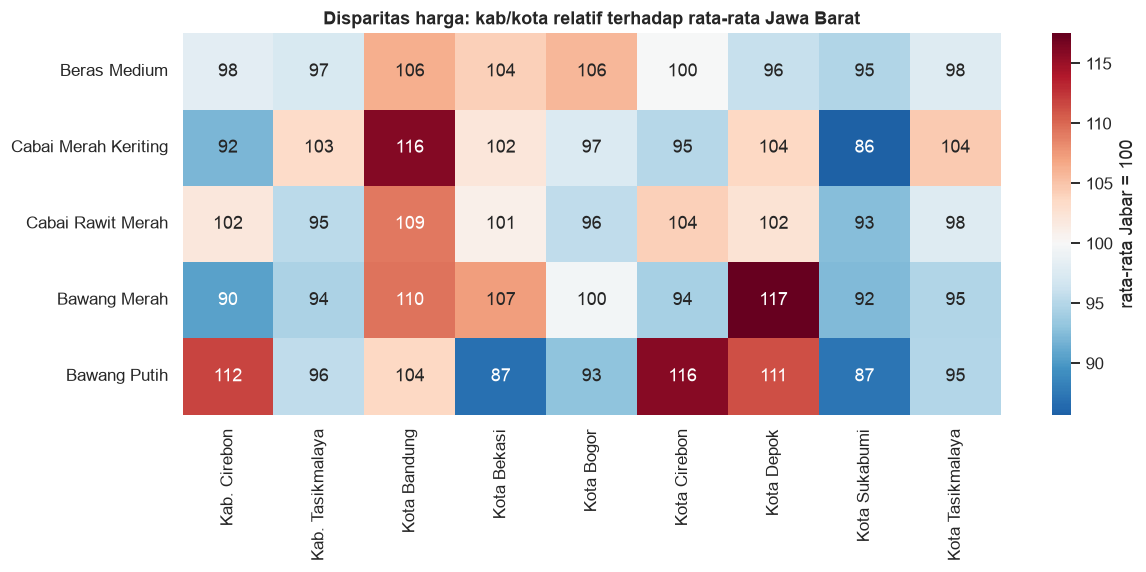

In [25]:
rel = wk.copy()
rel["rel"] = rel.harga_isi / rel.groupby(["tanggal", "komoditas"]).harga_isi.transform("mean") * 100
disp = rel.groupby(["komoditas", "kabkota"]).rel.mean().unstack().loc[KOM]
ax = sns.heatmap(disp, annot=True, fmt=".0f", cmap="RdBu_r", center=100, cbar_kws={"label": "rata-rata Jabar = 100"})
ax.set_title("Disparitas harga: kab/kota relatif terhadap rata-rata Jawa Barat"); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

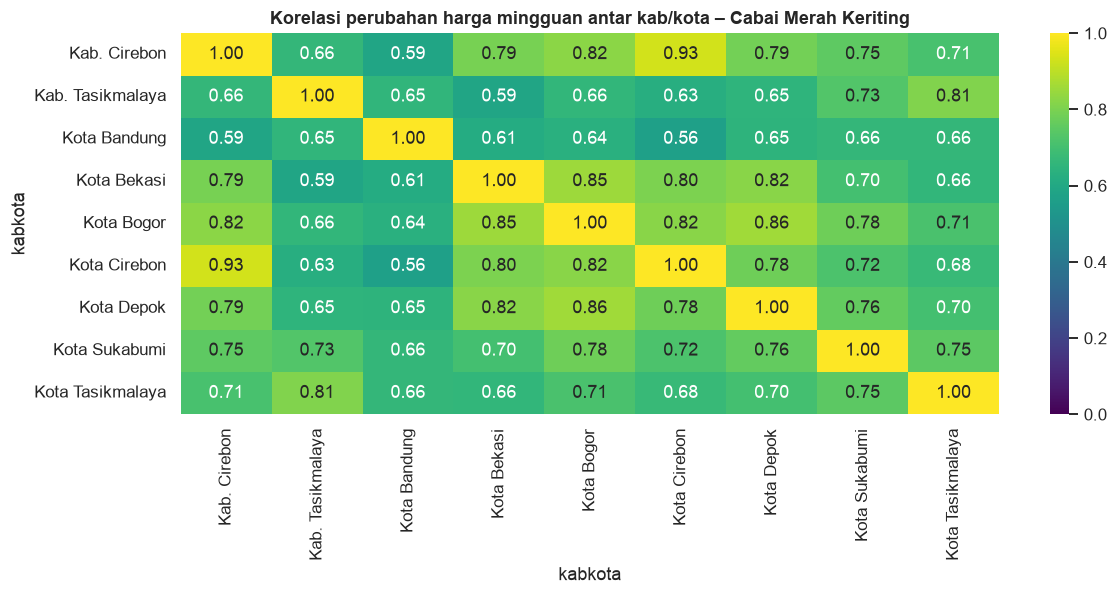

Rata-rata korelasi antar daerah: 0.72


In [26]:
k = "Cabai Merah Keriting"
r = wk[wk.komoditas == k].pivot(index="tanggal", columns="kabkota", values="ret")
ax = sns.heatmap(r.corr(), annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
ax.set_title(f"Korelasi perubahan harga mingguan antar kab/kota – {k}"); plt.show()
print(f"Rata-rata korelasi antar daerah: {r.corr().values[np.triu_indices(len(r.columns), 1)].mean():.2f}")

Korelasi antar daerah yang tinggi berarti guncangan harga menjalar ke seluruh Jawa Barat —
informasi harga di satu daerah berguna sebagai **fitur prediktor** untuk daerah lain.

## 9. Autokorelasi & stasioneritas (dasar pemodelan)

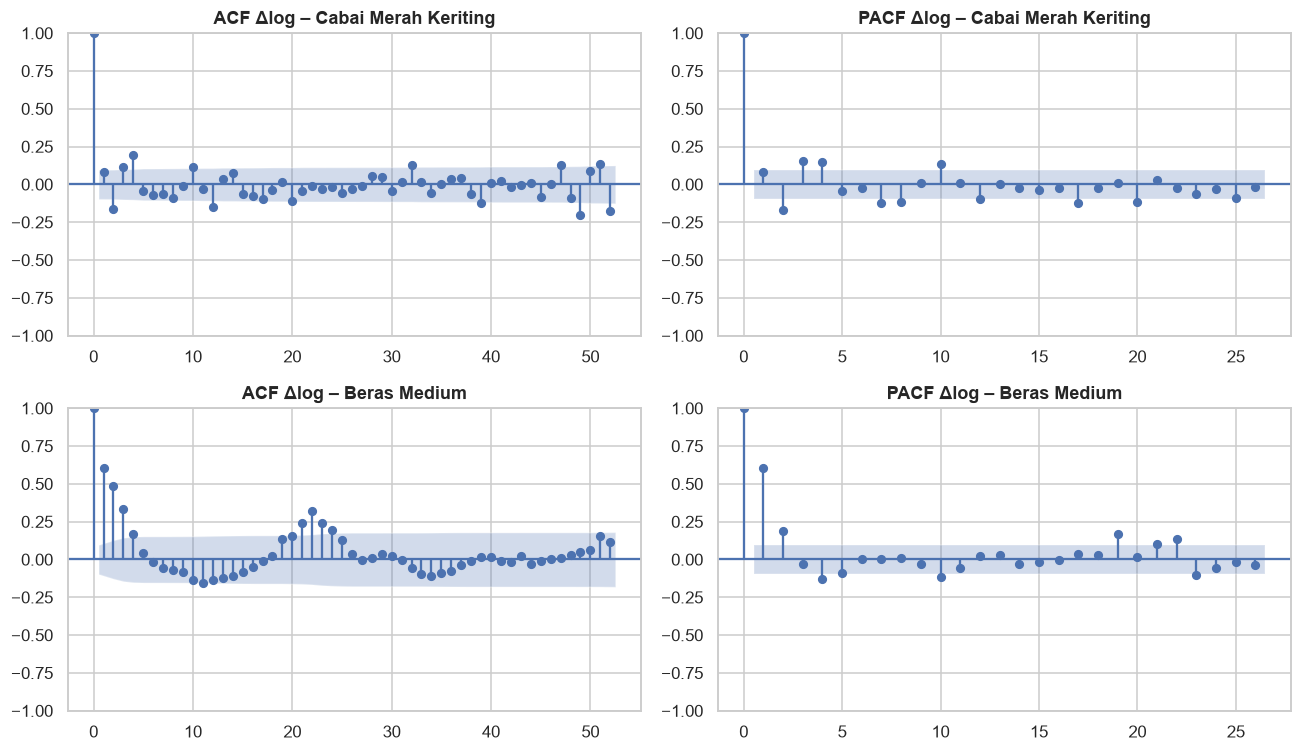

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, k in enumerate(["Cabai Merah Keriting", "Beras Medium"]):
    s = jabar[k].dropna()
    plot_acf(np.log(s).diff().dropna(), lags=52, ax=axes[i, 0], title=f"ACF Δlog – {k}")
    plot_pacf(np.log(s).diff().dropna(), lags=26, ax=axes[i, 1], title=f"PACF Δlog – {k}", method="ywm")
plt.tight_layout(); plt.show()

In [28]:
adf = []
for k in KOM:
    s = np.log(jabar[k].dropna())
    adf.append({"komoditas": k,
                "p-value ADF (level)": adfuller(s, autolag="AIC")[1],
                "p-value ADF (Δlog)":  adfuller(s.diff().dropna(), autolag="AIC")[1]})
pd.DataFrame(adf).set_index("komoditas").style.format("{:.4f}") \
  .set_caption("Uji Augmented Dickey-Fuller (p < 0,05 = stasioner)")

,p-value ADF (level),p-value ADF (Δlog)
komoditas,,
Beras Medium,0.9525,0.0000
Cabai Merah Keriting,0.0001,0.0000
Cabai Rawit Merah,0.0000,0.0000
Bawang Merah,0.0001,0.0000
Bawang Putih,0.0582,0.0000


## 10. Ekspor data mingguan untuk notebook analisis

In [29]:
out = Path("..") / "data/processed"
out.mkdir(parents=True, exist_ok=True)
wk[["tanggal", "kabkota", "komoditas", "harga", "harga_isi"]].to_csv(out / "harga_mingguan_fokus.csv", index=False)
print("Tersimpan:", out / "harga_mingguan_fokus.csv", "|", len(wk), "baris")

Tersimpan: ../data/processed/harga_mingguan_fokus.csv | 18585 baris


## 11. Ringkasan temuan EDA

**Ketersediaan & kualitas data (komponen f)**
- PIHPS menyediakan **389.529 observasi harian** (21 komoditas × 9 kab/kota, 1 Jan 2019 – 24 Nov 2026, hari kerja saja).
  Untuk 5 komoditas fokus tersedia 92.745 observasi dengan **nilai hilang hanya 3,4 %**, tanpa duplikat dan tanpa harga ≤ 0.
- Ditemukan **3 titik salah input** (lonjakan >190 % lalu turun ±69 % keesokan harinya, semuanya cabai rawit merah
  di Kota Depok & Kota Sukabumi) yang dibersihkan sebelum agregasi mingguan.
- **Keterbatasan:** hanya 9 dari 27 kab/kota Jawa Barat yang dipantau PIHPS (dominan wilayah perkotaan);
  data bersumber dari pasar tradisional (bukan pasar modern); beberapa seri cabai/bawang memiliki rentang harga
  datar yang panjang (kemungkinan laporan tidak diperbarui).

**Pola harga (komponen g)**
1. **Cabai & bawang jauh lebih bergejolak daripada beras.** CV cabai rawit merah 39 %, cabai merah keriting 36 %,
   bawang merah 27 %, bawang putih 23 %, beras medium hanya 14 %.
2. **Lonjakan sering terjadi.** Persentase minggu dengan kenaikan > 10 % dalam 4 minggu: cabai rawit merah 38,6 %,
   cabai merah keriting 33,2 %, bawang merah 28,6 %, bawang putih 10,1 %, beras medium 0,8 %.
   → Lonjakan bukan kejadian langka sehingga layak dibuat sistem peringatan dini.
3. **Tren naik jangka panjang.** Dibanding 2019, rata-rata 2026 lebih tinggi: cabai rawit +58 %, bawang merah +42 %,
   beras medium +35 % (lompatan struktural 2023–2024), cabai merah keriting +34 %, bawang putih +15 %.
4. **Musiman berbeda per komoditas.** Cabai mahal di Desember–Maret (musim hujan; indeks cabai rawit 115–127)
   dan murah Mei–Juni / Sep–Nov. Bawang merah memuncak April–Juni (indeks ±119) lalu turun tajam Agustus–Oktober (80–84).
   Kekuatan musiman tertinggi pada bawang merah; cabai lebih didominasi guncangan tak beraturan.
5. **Disparitas antar daerah.** Kota Bandung konsisten paling mahal (cabai merah keriting 16 % di atas rata-rata Jabar),
   Kota Sukabumi paling murah (14 % di bawah rata-rata).
6. **Guncangan harga menjalar antar daerah.** Korelasi perubahan harga mingguan antar kab/kota: cabai rawit 0,77,
   cabai merah keriting 0,72, bawang 0,62–0,64, beras 0,33 → harga daerah lain berguna sebagai fitur prediksi.
7. **Ada memori jangka pendek.** Seri Δlog harga stasioner (ADF p < 0,001) dan autokorelasi lag-1 positif
   (beras 0,61; cabai rawit 0,46; bawang merah 0,47) → harga beberapa minggu terakhir informatif untuk prediksi.

**Implikasi untuk pemodelan (notebook 02)**
- Target: harga 1–4 minggu ke depan, per kab/kota × komoditas (data mingguan, 18.585 baris).
- Fitur: lag harga, perubahan 4 minggu, musim (bulan/minggu ke-), jarak ke Idulfitri, rata-rata harga daerah lain.
- Pembanding non-AI wajib: *naive* (harga minggu lalu), *seasonal naive*, dan rata-rata bergerak — untuk menguji
  apakah AI benar-benar diperlukan (komponen e).
- Fokus utama peringatan dini: cabai merah keriting, cabai rawit merah, dan bawang merah; beras berperan sebagai kontrol stabil.